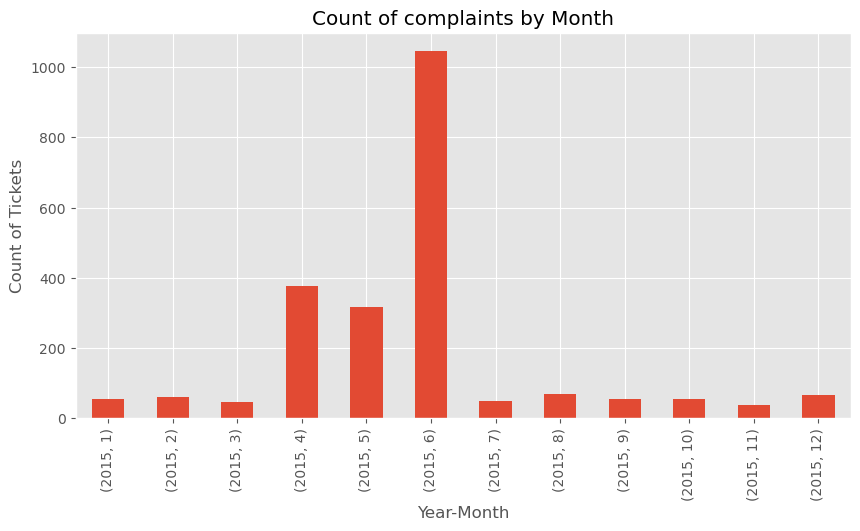

In [138]:
#Project 3 :Comcast Telecom Consumer Complaints 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
import os
import datetime
import matplotlib.dates as mdates
os.getcwd()
os.chdir("C:\\datasets\\")

#############################Import data into Python environment
#Import data into Python environment
df=pd.read_csv('Comcast_telecom_complaints_data.csv')
x=df['Date_month_year']
#DatetimeIndex is a specialized index object that manages and utilizes time-based data in a DataFrame or Series
df['month'] = pd.DatetimeIndex(df['Date_month_year']).month
df['year'] = pd.DatetimeIndex(df['Date_month_year']).year
y_m=df['year'].map(str)+'-'+df['month'].map(str)
df['year-month']=y_m
year_order=df.sort_values(by=['year'])
month_order=year_order.sort_values(by=['month'])
month_order.head()
#month_values= month_order.set_index(field).loc[month_order].plot(kind="bar", legend=False)
month_values=month_order.groupby(['year','month'])['Ticket #'].count().plot(kind='bar',figsize=(10,5))
plt.xlabel('Year-Month')
plt.ylabel('Count of Tickets')
plt.title('Count of complaints by Month')
plt.rcParams["font.size"] = 20
#plt.grid()
plt.show()
#Provide the trend chart for the number of complaints at Monthly level.
#############################Provide the trend chart for the number of complaints at monthly level.




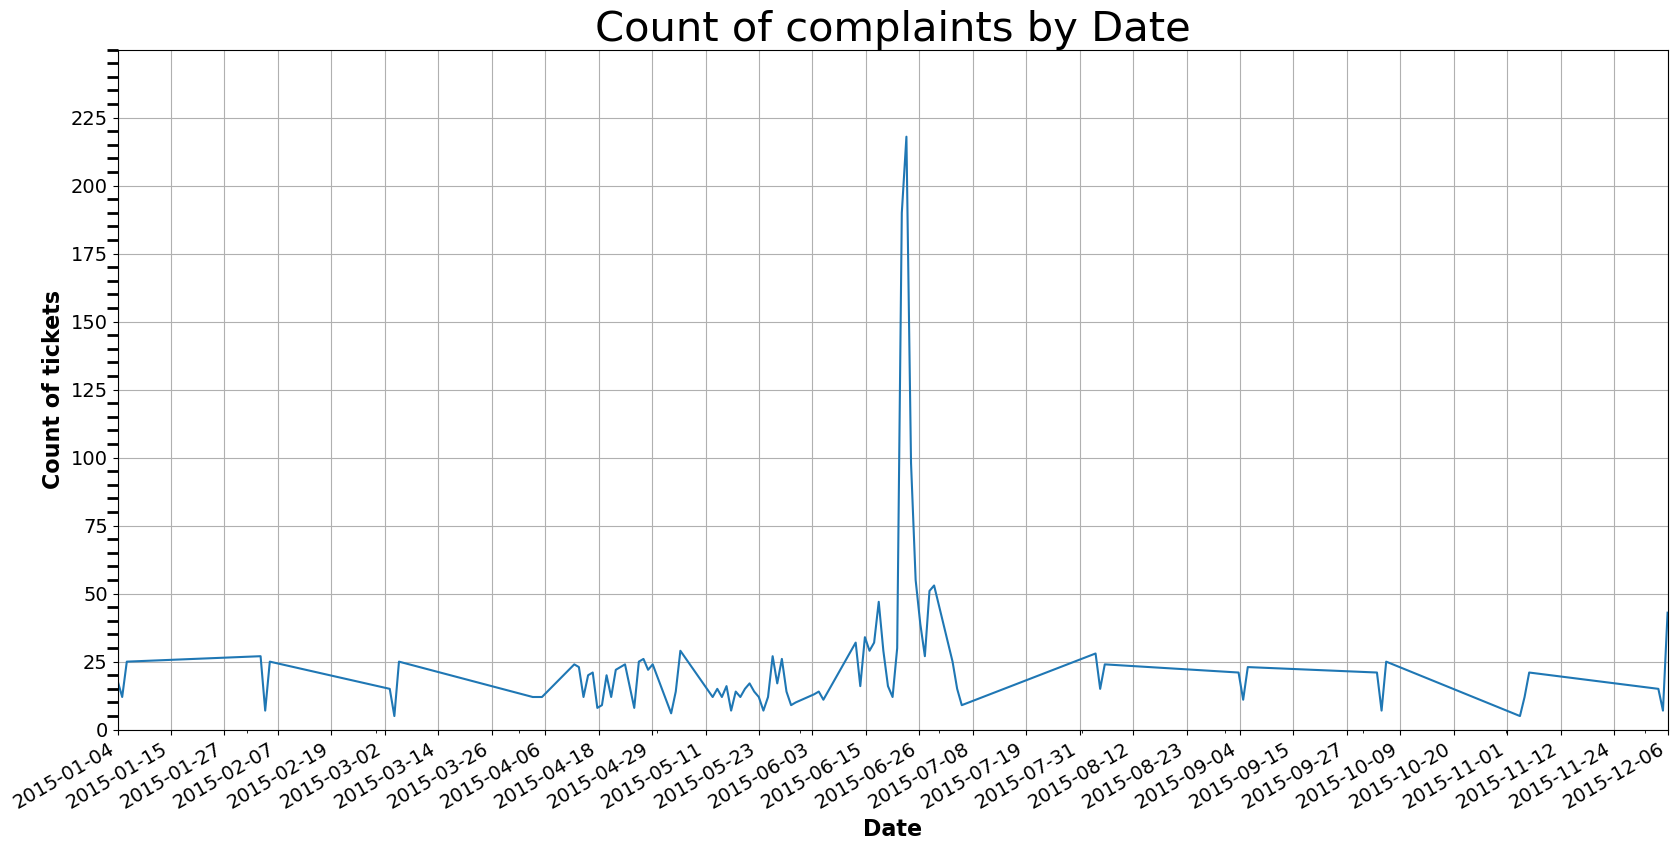

In [17]:
df['Date']=pd.to_datetime(df['Date'])
df['Date_month_year']=pd.to_datetime(df['Date_month_year'])
#df.sort_values(['Date_month_year'])
#############Provide the trend chart for the number of complaints at Daily granularity level
#plt.figure(figsize=(20,10))
# Figure is the entire window or canvas,
# while a plot (technically an Axes object) is an individual graphic that resides within that figure.
fig, ax = plt.subplots(figsize=(20,10))
years = mdates.YearLocator()   # every year
months = mdates.MonthLocator()  #every month
min1=min(df['Date_month_year'])
max1=max(df['Date_month_year'])
years_fmt = mdates.DateFormatter('%Y-%m-%d')
day_values=df.groupby(['Date_month_year'])['Ticket #'].count().plot(kind='line')
# format the ticks
ax.xaxis.set_major_locator(years)
ax.xaxis.set_major_formatter(years_fmt)
ax.xaxis.set_minor_locator(months)
plt.xlabel('Date', fontsize=16,fontweight='bold')
plt.ylabel('Count of tickets', fontsize=16,fontweight='bold')
plt.title('Count of complaints by Date', fontsize=30)
plt.xticks(pd.date_range(min1,max1,30),fontsize=14)
plt.yticks(np.arange(0,250,25),fontsize=14)
#date_formatter = mdates.DaDateplt.xticks(fontsize=14)
plt.axis([min1, max1, 0, 250])
ax.yaxis.set_minor_locator(plt.MultipleLocator(5))
plt.tick_params(axis="y",which="minor",length=8,width='2')
fig.autofmt_xdate()
plt.grid()
#ax.fmt_xdata = mdates.DateFormatter('%Y-%m-%d')  
plt.show()

In [18]:
################################Provide a table with the frequency of complaint types.
c_types=df.groupby(['Received Via'])['Ticket #'].count()

df.rename(columns = {'Received Via':'Complaint Type'}, inplace = True) 
pd.crosstab(index=df['Complaint Type'], columns='count')



col_0,count
Complaint Type,
Customer Care Call,1119
Internet,1105


In [37]:
###############State with the max complaints

df.head(10)
df_subtotal=df.groupby(['State'])['Customer Complaint'].count()
#sort series
df_subtotal.sort_values(ascending=False)
a=max(df_subtotal)
print('Max number of complaints was received for',df_subtotal.idxmax(),':', a)



Max number of complaints was received for Georgia : 288


In [50]:
###########Which state has the highest percentage of unresolved complaints
df.head(10)
c_states_UNresolved = df[df['Status'] =='Open'] 
c_states_UNresolved=c_states_UNresolved.groupby(['State'])['Ticket #'].count()
# Number of # Number of unresolved complaints
c_states_UNresolved.to_frame()
#TOTAL Nbr of complaints by State
c_state_all=df.groupby(['State'])['Ticket #'].count()
c_state_all=c_state_all.to_frame()
#merging dataframes unresolved and all complaits
df_UNresolved_perc=pd.merge(c_state_all,c_states_UNresolved,on=['State'], how='left')
#calculating percent of unresolved complaints
df_UNresolved_perc['Ticket #_y'].replace(np.nan,0)
df_UNresolved_perc['Ticket #_x'].replace(np.nan,0)
df_UNresolved_perc['percent UNresolved']=df_UNresolved_perc['Ticket #_y']/df_UNresolved_perc['Ticket #_x']
df_UNresolved=df_UNresolved_perc['percent UNresolved']
a=max(df_UNresolved)
df_UNresolved.idxmax()
print("State of "+df_UNresolved.idxmax()+" has maximum percent of unresolved complains: "+"{:.2%}".format(a))

State of Maine has maximum percent of unresolved complains: 40.00%


In [51]:
#Project 3 :Comcast Telecom Consumer Complaints 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
import os
import datetime
import matplotlib.dates as mdates
os.getcwd()
os.chdir("C:\\datasets\\")

In [43]:
################################Which complaint types are maximum
#complain count by type
#c_types.max(level=0)
#df.groupby('City')['Ticket #'].mean().reset_index()
print('Max number of complaints was received for',df.groupby(['City']).count())
#df.head()

Max number of complaints was received for              Ticket #  Customer Complaint  Date  Date_month_year  Time  \
City                                                                     
Abingdon            1                   1     1                1     1   
Acworth             6                   6     6                6     6   
Adrian              1                   1     1                1     1   
Alameda             2                   2     2                2     2   
Albuquerque         5                   5     5                5     5   
...               ...                 ...   ...              ...   ...   
York                4                   4     4                4     4   
York Haven          1                   1     1                1     1   
Yorkville           1                   1     1                1     1   
Youngstown          1                   1     1                1     1   
Ypsilanti           4                   4     4                4     4

In [55]:
#Provide the percentage of complaints resolved till date,
#which were received through the Internet and customer care calls.
c_resolved=df[df['Status'] =='Closed'] .groupby(['Complaint Type','Date_month_year'])['Ticket #'].count()
c_total=df.groupby(['Complaint Type','Date_month_year'])['Ticket #'].count()
df_total_count=pd.merge(c_total,c_resolved,on=['Complaint Type','Date_month_year'], how='left')
df_total_count.rename(columns = {'Ticket #_x':'count_total'}, inplace = True) 
df_total_count.rename(columns = {'Ticket #_y':'count_resolved'}, inplace = True) 
df_summary=df_total_count.groupby([ 'Complaint Type','Date_month_year']).sum().groupby( level=0). \
cumsum().reset_index()
df_summary['percentage of complaints resolved till date']= \
100*(df_summary['count_resolved']/df_summary['count_total'])
df_summary.head(100)

,Complaint Type,Date_month_year,count_total,count_resolved,percentage of complaints resolved till date
0,Customer Care Call,2015-01-04,12,12.0,100.000000
1,Customer Care Call,2015-01-05,19,14.0,73.684211
2,Customer Care Call,2015-01-06,32,24.0,75.000000
3,Customer Care Call,2015-02-04,45,36.0,80.000000
4,Customer Care Call,2015-02-05,50,38.0,76.000000
...,...,...,...,...,...
95,Internet,2015-02-05,39,30.0,76.923077
96,Internet,2015-02-06,46,36.0,78.260870
97,Internet,2015-03-04,56,44.0,78.571429
98,Internet,2015-03-06,71,49.0,69.014085


In [56]:
#export Percent of resolved complaints till date to excel
df_summary.sort_values(by=['Complaint Type','Date_month_year'], ascending=True)
df_summary.to_excel(r'Project3_cumsum.xlsx', index = False)
df_total_count.to_excel(r'Project3_count.xlsx', index = False)

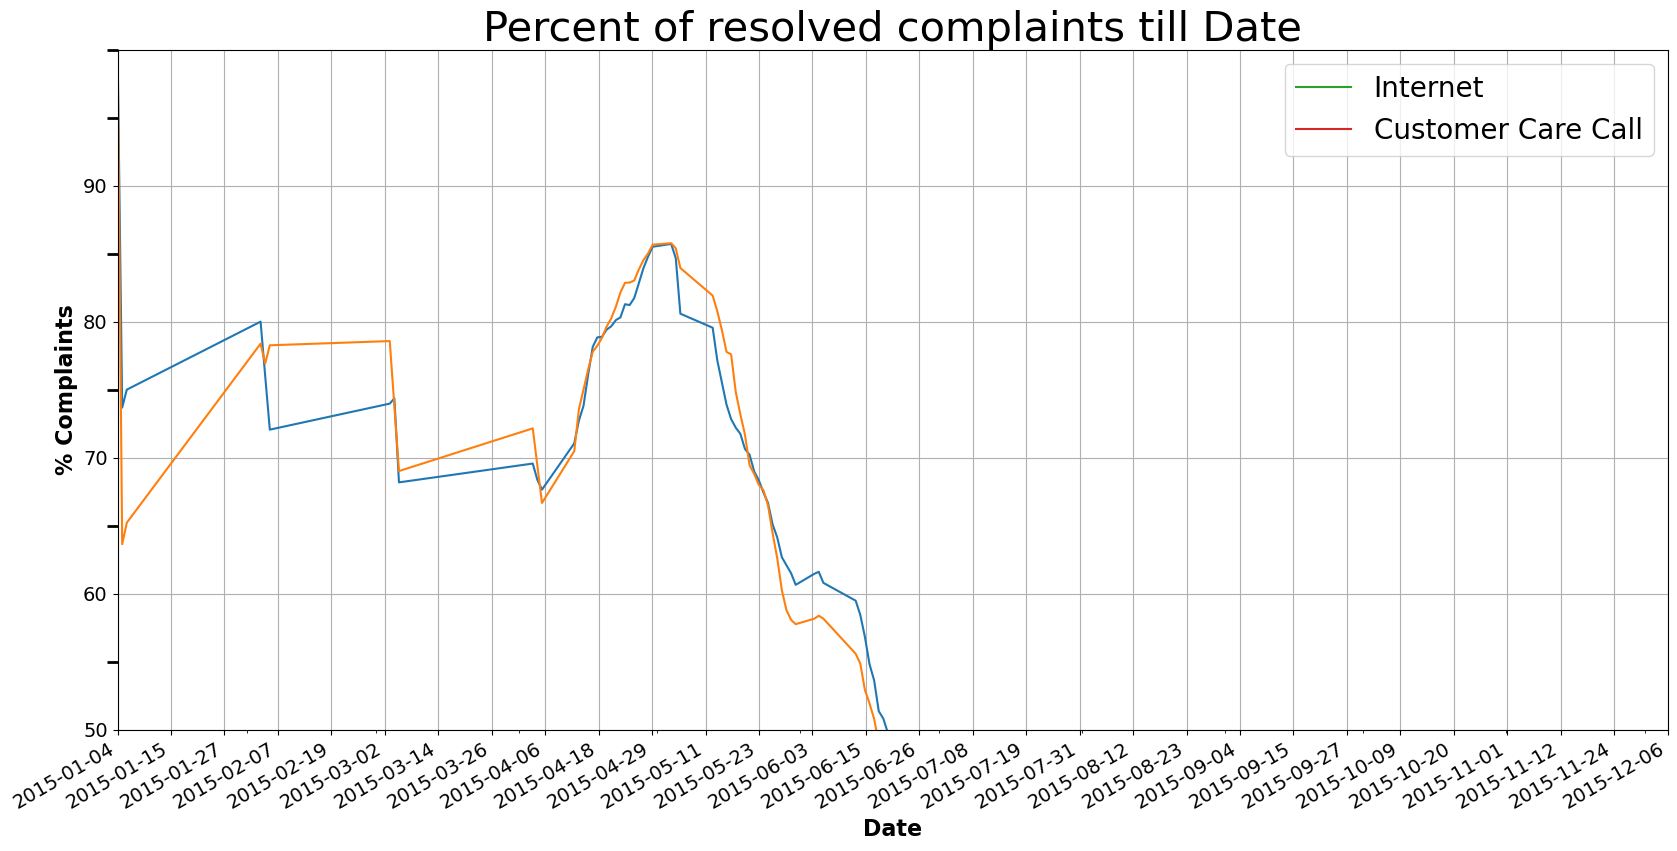

In [57]:
fig, ax = plt.subplots(figsize=(20,10))
years = mdates.YearLocator()   # every year
months = mdates.MonthLocator()  #every month
min1=min(df_summary['Date_month_year'])
max1=max(df_summary['Date_month_year'])
years_fmt = mdates.DateFormatter('%Y-%m-%d')
df_summary[df_summary['Complaint Type']=='Customer Care Call']. \
groupby(['Date_month_year'])['percentage of complaints resolved till date'] \
.max().plot(kind='line')
df_summary[df_summary['Complaint Type']=='Internet']. \
groupby(['Date_month_year'])['percentage of complaints resolved till date'] \
.max().plot(kind='line')
# format the ticks
ax.xaxis.set_major_locator(years)
ax.xaxis.set_major_formatter(years_fmt)
ax.xaxis.set_minor_locator(months)
plt.xlabel('Date', fontsize=16,fontweight='bold')
plt.ylabel('% Complaints', fontsize=16,fontweight='bold')
plt.title('Percent of resolved complaints till Date', fontsize=30)
plt.xticks(pd.date_range(min1,max1,30),fontsize=14)
plt.yticks(np.arange(50,100,10),fontsize=14)
#date_formatter = mdates.DaDateplt.xticks(fontsize=14)
plt.axis([min1, max1, 50, 100])
ax.yaxis.set_minor_locator(plt.MultipleLocator(5))
plt.tick_params(axis="y",which="minor",length=8,width='2')
ax.legend(loc=1,prop={'size':12})
line_up, = plt.plot([1,2,3], label='Internet')
line_down, = plt.plot([3,2,1], label='Customer Care Call')
plt.legend(handles=[line_up, line_down])
fig.autofmt_xdate()
plt.grid()
#ax.fmt_xdata = mdates.DateFormatter('%Y-%m-%d')  
plt.show()

In [58]:
#Import the required library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
#sns.set(font_scale=1.35, style="ticks")

In [59]:
#View the plot in notebook
%matplotlib inline

In [61]:
#Import the dataset
df_auto_data=pd.read_csv('Auto.csv')

In [62]:
#View the top 5 reords
df_auto_data.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [63]:
#Write a user-defined function for origin
def origin(num):
    if num==1:
        return 'USA'
    elif num==2:
        return 'Europe'
    else:
        return 'Asia'  
        
#use apply function
df_auto_data['origin']=df_auto_data['origin'].apply(origin)  

In [64]:
#view first 30 data points 
df_auto_data.head(30)

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
0,18.0,8,307.0,130,3504,12.0,70,USA,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,USA,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,USA,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,USA,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,USA,ford torino
5,15.0,8,429.0,198,4341,10.0,70,USA,ford galaxie 500
6,14.0,8,454.0,220,4354,9.0,70,USA,chevrolet impala
7,14.0,8,440.0,215,4312,8.5,70,USA,plymouth fury iii
8,14.0,8,455.0,225,4425,10.0,70,USA,pontiac catalina
9,15.0,8,390.0,190,3850,8.5,70,USA,amc ambassador dpl


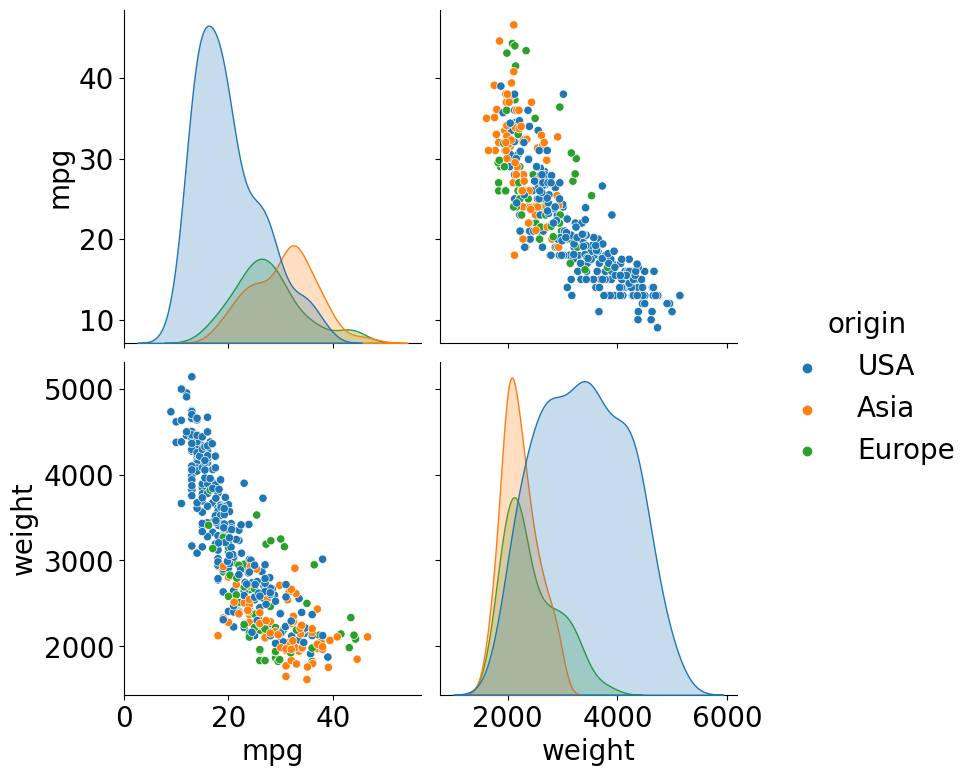

In [66]:
sns.pairplot(df_auto_data[['mpg','weight','origin''']],hue='origin',height=4)

In [67]:
#############Web site traffic plot
import matplotlib.pyplot as plt
from matplotlib import style
%matplotlib inline
web_mon=[111,234,55,333,555,456,579,377,355,779,122]
web_tue=[1,33,535,33,55,435,59,377,355,779,122]
web_wed=[111,24,55,33,555,536,79,377,35,779,1228]
time_hrs=[7,8,9,10,11,12,14,16,17,18,26]

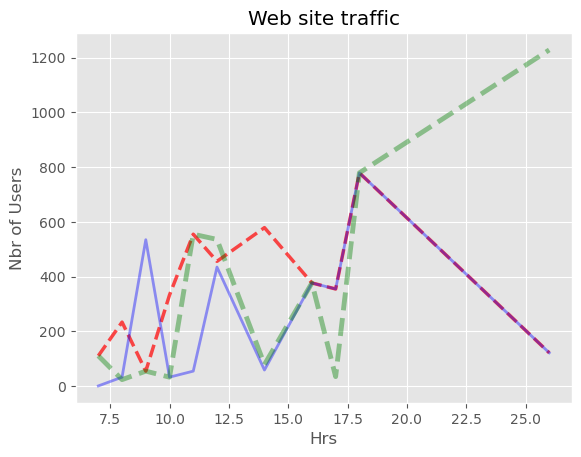

In [68]:
style.use('ggplot')
plt.plot(time_hrs,web_mon,color='r',label='Mon',linestyle='--',linewidth=2.5,alpha=.7)
plt.plot(time_hrs,web_tue,color='b',label='Tue',linestyle='-',linewidth=2,alpha=.4)
plt.plot(time_hrs,web_wed,color='g',label='Wed',linestyle='--',linewidth=3.5,alpha=.4)

plt.title('Web site traffic')
plt.xlabel('Hrs')
plt.ylabel('Nbr of Users')
plt.show()

In [80]:
 #machine learning tasks : sklearn.dataset :Boston house prices dataset
from sklearn.datasets import load_boston
import matplotlib.pyplot as plt
from matplotlib import style
%matplotlib inline
boston_real_state_data=load_boston()
print(boston_real_state_data.DESCR)


.. _boston_dataset:

Boston house prices dataset
---------------------------

**Data Set Characteristics:**  

    :Number of Instances: 506 

    :Number of Attributes: 13 numeric/categorical predictive. Median Value (attribute 14) is usually the target.

    :Attribute Information (in order):
        - CRIM     per capita crime rate by town
        - ZN       proportion of residential land zoned for lots over 25,000 sq.ft.
        - INDUS    proportion of non-retail business acres per town
        - CHAS     Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
        - NOX      nitric oxides concentration (parts per 10 million)
        - RM       average number of rooms per dwelling
        - AGE      proportion of owner-occupied units built prior to 1940
        - DIS      weighted distances to five Boston employment centres
        - RAD      index of accessibility to radial highways
        - TAX      full-value property-tax rate per $10,000
        - PTRATIO  pu

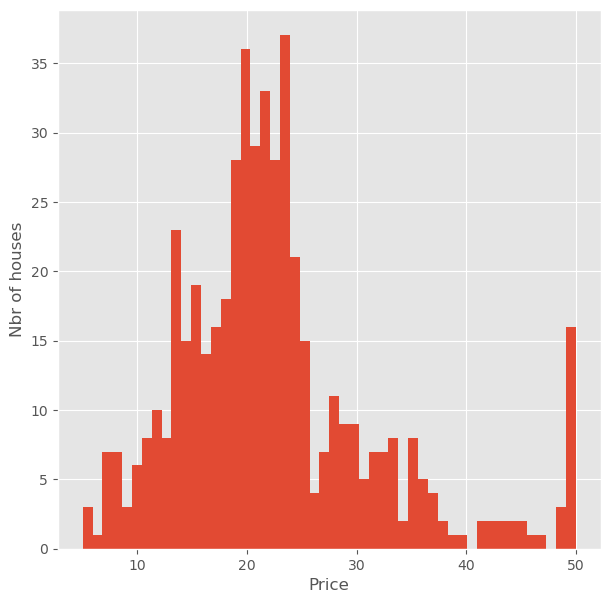

In [81]:


x_axis=boston_real_state_data.data
y_axis=boston_real_state_data.target
style.use('ggplot')
plt.figure(figsize=(7,7))
plt.hist(y_axis,bins=50)
plt.xlabel('Price')
plt.ylabel('Nbr of houses')
plt.show()




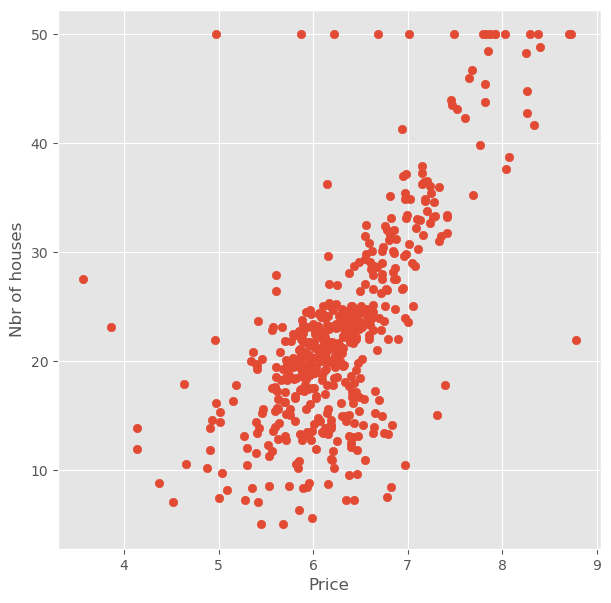

In [82]:
style.use('ggplot')
plt.figure(figsize=(7,7))
plt.scatter(boston_real_state_data.data[:,5],boston_real_state_data.target)
plt.xlabel('Price')
plt.ylabel('Nbr of houses')
plt.show()

In [91]:
########Seaborn : Flights dataset
import matplotlib.pyplot as plt
from matplotlib import style
%matplotlib inline
import seaborn as sns
%matplotlib inline

In [92]:
flights_data=sns.load_dataset('flights')

In [94]:
flights_data.head()


,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [95]:
flights_data=flights_data.pivot('month','year','passengers')


In [96]:
#passengers bt year/month
flights_data.head()

year,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
month,,,,,,,,,,,,
Jan,112,115,145,171,196,204,242,284,315,340,360,417
Feb,118,126,150,180,196,188,233,277,301,318,342,391
Mar,132,141,178,193,236,235,267,317,356,362,406,419
Apr,129,135,163,181,235,227,269,313,348,348,396,461
May,121,125,172,183,229,234,270,318,355,363,420,472


<AxesSubplot:xlabel='year', ylabel='month'>

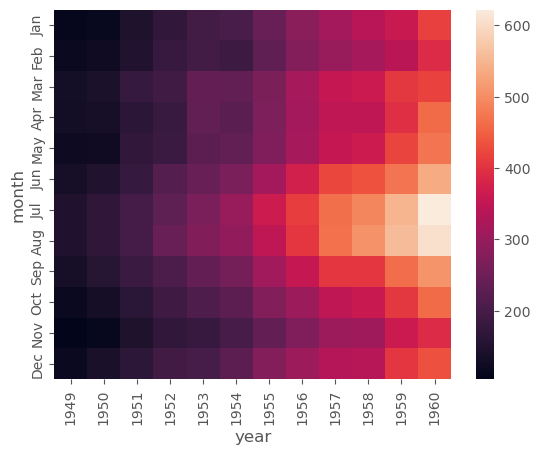

In [97]:
sns.heatmap(flights_data)

In [98]:
##Pie chart example: Job count by Type
job_data=['10','133','22','22','7','44']

In [99]:
labels='IT','Marketing','Admin','Operations','HR','Finance'

In [100]:
explode=(0.5,0,0,0,0,0)

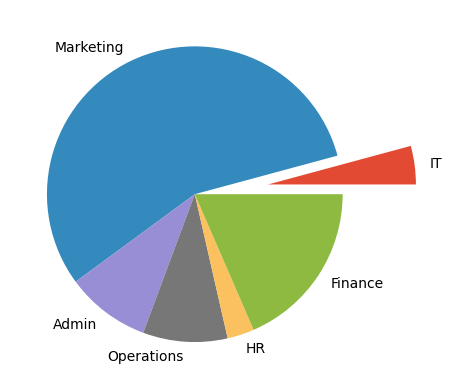

In [101]:
plt.pie(job_data,labels=labels,explode=explode)
plt.show()

In [118]:
# Spam collection
#Grid Search and Plotting
import pandas as pd
import string
from pprint import pprint
from time import time

import os
import datetime
import matplotlib.dates as mdates
os.getcwd()
os.chdir("C:\\datasets\\")
df_spam_collection=pd.read_csv('SMSSpamCollection.csv',sep='\t',names=['response','message'])

In [119]:
df_spam_collection.head()


,response,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [120]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

In [121]:
#Create a Pipeline
#CountVectorizer is a class in the sklearn.feature_extraction.text module of the scikit-learn library.
#It is used to convert a collection of text documents into a matrix of token counts
#TfidfTransformer in scikit-learn is used to convert a count matrix (e.g., from CountVectorizer)
#into a TF-IDF (Term Frequency–Inverse Document Frequency) representation.
pip=Pipeline([('vect',CountVectorizer())
              ,('tfidf',TfidfTransformer()),
             ('clf',SGDClassifier())])

In [136]:
parameters={'tfidf_use_idf':(True,False)}
print(parameters)

{'tfidf_use_idf': (True, False)}


In [137]:
# Create the GridSearchCV object
grid_search=GridSearchCV(pip,parameters,n_jobs=1,verbose=1)
print(grid_search)

GridSearchCV(estimator=Pipeline(steps=[('vect', CountVectorizer()),
                                       ('tfidf', TfidfTransformer()),
                                       ('clf', SGDClassifier())]),
             n_jobs=1, param_grid={'tfidf_use_idf': (True, False)}, verbose=1)


In [134]:
print('Performing Grid search now...')
print('Parameters:')
print(parameters)
t0=time()
#grid_search.fit(df_spam_collection['message'],df_spam_collection['response'])
print('Done in %0.3fs'%(time()-t0))
print()

Performing Grid search now...
Parameters:
{'tfidf_use_idf': (True, False)}
Done in 0.000s

